# Heart Disease Prediction System

**Dataset:** UCI Heart Disease Dataset — Cleveland  
**Algorithm:** Random Forest Classifier  
**Input features:** `age`, `sex`, `cp`, `thalach`  
**Target:** `num`, converted to binary classification  
**Evaluation metrics:** Accuracy, precision, recall, F1-score, confusion matrix


In [2]:
%pip install scikit-learn==1.7.2

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import sklearn
print(sklearn.__version__)

1.7.2


## 1. Import Libraries

In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

RANDOM_STATE = 42


## 2. Load the Dataset

In [5]:
columns = [
    "age", "sex", "cp", "trestbps", "chol",
    "fbs", "restecg", "thalach", "exang",
    "oldpeak", "slope", "ca", "thal", "num"
]

DATA_PATH = "processed.cleveland.data"

df = pd.read_csv(
    DATA_PATH,
    header=None,
    names=columns,
    na_values="?"
)

print("Dataset shape:", df.shape)
display(df.head())


Dataset shape: (303, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


## 3. Inspect and Prepare the Data

In [6]:
print("Missing values by column:")
print(df.isna().sum())

print("\nOriginal target distribution:")
print(df["num"].value_counts(dropna=False).sort_index())


Missing values by column:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
num         0
dtype: int64

Original target distribution:
num
0    164
1     55
2     36
3     35
4     13
Name: count, dtype: int64


In [7]:
features = ["age", "sex", "cp", "thalach"]
target = "num"

df = df.dropna(subset=features + [target]).copy()

X = df[features].astype(float)
y = (df[target].astype(int) > 0).astype(int)

print("Selected input features:", features)
print("Number of input features:", len(features))
print("Target: 0 = no disease, 1 = disease present")
print("\nBinary target distribution:")
print(y.value_counts().sort_index())


Selected input features: ['age', 'sex', 'cp', 'thalach']
Number of input features: 4
Target: 0 = no disease, 1 = disease present

Binary target distribution:
num
0    164
1    139
Name: count, dtype: int64


## 4. Split the Dataset

In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Number of input features:", X_train.shape[1])


Training samples: 242
Testing samples: 61
Number of input features: 4


## 5. Train the Model

In [9]:
model = RandomForestClassifier(
    n_estimators=200,
    random_state=RANDOM_STATE,
    class_weight="balanced"
)

model.fit(X_train, y_train)
print("Model training completed.")


Model training completed.


## 6. Evaluate the Model

In [10]:
y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy: {accuracy:.4f} ({accuracy * 100:.2f}%)")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["No disease (0)", "Disease present (1)"],
    zero_division=0
))

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
print("Confusion Matrix:")
print(cm)


Accuracy: 0.7869 (78.69%)

Classification Report:
                     precision    recall  f1-score   support

     No disease (0)       0.81      0.79      0.80        33
Disease present (1)       0.76      0.79      0.77        28

           accuracy                           0.79        61
          macro avg       0.79      0.79      0.79        61
       weighted avg       0.79      0.79      0.79        61

Confusion Matrix:
[[26  7]
 [ 6 22]]


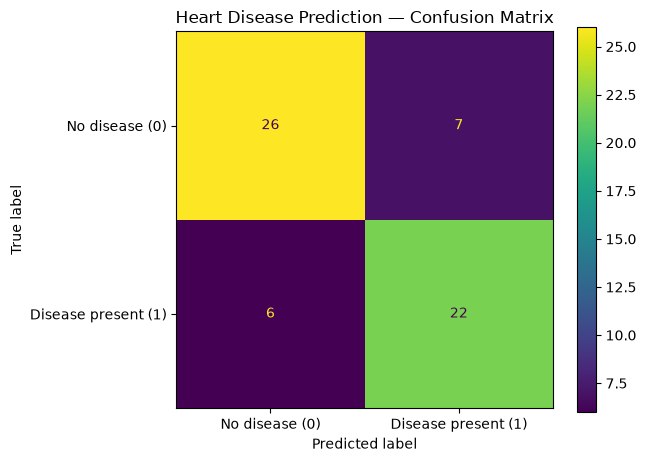

In [11]:
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No disease (0)", "Disease present (1)"]
)
disp.plot()
plt.title("Heart Disease Prediction — Confusion Matrix")
plt.tight_layout()
plt.show()


## 7. Feature Importance

,Feature,Importance
3,thalach,0.370542
0,age,0.306476
2,cp,0.230616
1,sex,0.092365


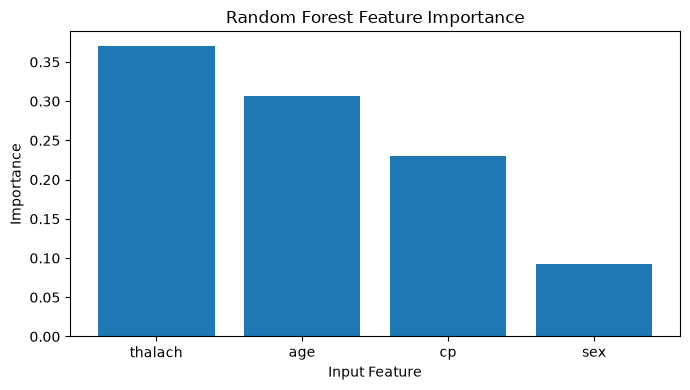

In [12]:
importance = pd.DataFrame({
    "Feature": features,
    "Importance": model.feature_importances_
}).sort_values("Importance", ascending=False)

display(importance)

plt.figure(figsize=(7, 4))
plt.bar(importance["Feature"], importance["Importance"])
plt.xlabel("Input Feature")
plt.ylabel("Importance")
plt.title("Random Forest Feature Importance")
plt.tight_layout()
plt.show()


## 8. Save the Trained Model

In [13]:
model_artifact = {
    "model": model,
    "features": features,
    "target_mapping": {
        0: "No disease detected in dataset",
        1: "Disease present in dataset"
    }
}

MODEL_PATH = "heart_disease_model.pkl"
joblib.dump(model_artifact, MODEL_PATH)
print(f"Trained model saved to: {MODEL_PATH}")


Trained model saved to: heart_disease_model.pkl


## 9. Test a Sample Prediction

In [14]:
sample_patient = pd.DataFrame([{
    "age": 45,
    "sex": 1,
    "cp": 2,
    "thalach": 150
}], columns=features)

sample_prediction = int(model.predict(sample_patient)[0])
sample_label = (
    "Disease present in dataset"
    if sample_prediction == 1
    else "No disease detected in dataset"
)

display(sample_patient)
print("Predicted class:", sample_prediction)
print("Predicted label:", sample_label)


,age,sex,cp,thalach
0,45,1,2,150


Predicted class: 0
Predicted label: No disease detected in dataset


## 10. Project Summary

The Heart Disease Prediction System uses four input features (`age`, `sex`, `cp`, and `thalach`) to predict a binary target derived from the Cleveland dataset's `num` column. The model is evaluated on a held-out test set using classification metrics and a confusion matrix.

**Note:** This model is intended for educational use and is not a medical diagnostic tool.
